<a href="https://colab.research.google.com/github/SolonLIA/deep-learning-labs/blob/main/lab04/lab04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part I

In [2]:
#Unzip the Image File

!apt-get -qq install -y libarchive-tools
!mkdir -p /content/neu_raw
!bsdtar -xf /content/NEU-CLS.rar -C /content/neu_raw

from pathlib import Path
import shutil

classes = {
    "Cr": "crazing",
    "In": "inclusion",
    "Pa": "patches",
    "PS": "pitted_surface",
    "RS": "rolled_in_scale",
    "Sc": "scratches",
}
counts = {name: 0 for name in classes.values()}

for image in Path("/content/neu_raw").rglob("*.bmp"):
    code = image.stem.split("_")[0]
    folder = Path("/content/NEU") / classes[code]
    folder.mkdir(parents=True, exist_ok=True)
    shutil.copy2(image, folder / image.name)
    counts[classes[code]] += 1

print(counts)
assert all(count == 300 for count in counts.values())

Selecting previously unselected package libarchive-tools.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libarchive-tools_3.7.2-2ubuntu0.9_amd64.deb ...
Unpacking libarchive-tools (3.7.2-2ubuntu0.9) ...
Setting up libarchive-tools (3.7.2-2ubuntu0.9) ...
Processing triggers for man-db (2.12.0-4build2) ...
{'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted_surface': 300, 'rolled_in_scale': 300, 'scratches': 300}


Section 6,7,8,9,10,11

Device: cuda
Number of images: 1800
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled_in_scale', 'scratches']
Image shape: torch.Size([1, 64, 64])
Class: crazing


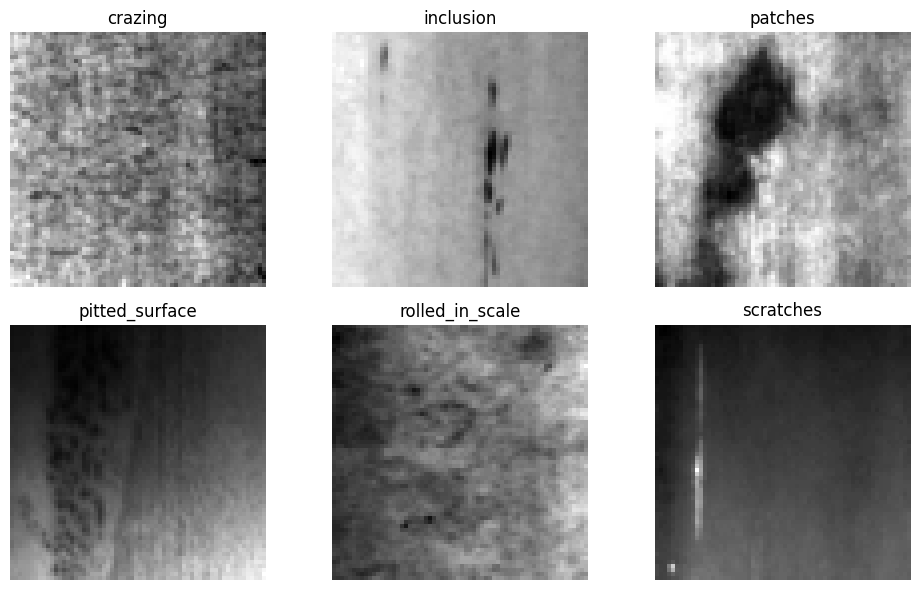

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (
 accuracy_score,
 classification_report,
 confusion_matrix,
 ConfusionMatrixDisplay
)

#Set random seed to 42
torch.manual_seed(42)


device = torch.device(
 "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

transform = transforms.Compose([
 transforms.Grayscale(num_output_channels=1),
 transforms.Resize((64, 64)),
 transforms.ToTensor()
])

dataset = datasets.ImageFolder(
 root="NEU",
 transform=transform
)
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)

image, label = dataset[0]
print("Image shape:", image.shape)
print("Class:", dataset.classes[label])

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, idx in zip(axes.flat, range(6)):
 image, label = dataset[idx * 300]
 ax.imshow(image.squeeze(), cmap="gray")
 ax.set_title(dataset.classes[label])
 ax.axis("off")
plt.tight_layout()
plt.show()


Question 1. Can you visually distinguish all six defect classes easily?

No, cazing and rolled in scale, inclusion and scratches, patches and pitted surface are all similar pairs visually.

Question 2. Which defect classes appear most similar?

Cazing and rolled in scale are similar, inclusion and scratches are similar, patches and pitted surface are similar.

Question 3. Why might these similarities make classification difficult?

Because they could introduce overlapping patterns between classes. Since the size change and greyscale, some details might be lost, which makes it harder for NN to learn features that reliably separate the classes.

Section 12,13

In [4]:
n = len(dataset)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val
train_set, val_set, test_set = random_split(
 dataset,
 [n_train, n_val, n_test],
 generator=torch.Generator().manual_seed(42)
)

batch_size = 32
train_loader = DataLoader(
 train_set,
 batch_size=batch_size,
 shuffle=True
)
val_loader = DataLoader(
 val_set,
 batch_size=batch_size,
 shuffle=False
)
test_loader = DataLoader(
 test_set,
 batch_size=batch_size,
 shuffle=False
)

Question 4. Why should the training data be shuffled?

Shuffling prevents the model from linking the patterns to sampling order, as well as distributes different classes across mini-bathces, which helps reduce bias in gradient updates and improves training stability.

Question 5. Why is shuffling less important for the test set?

Test set only used to evaluate performance, thus the samples order do not affect parameter updates.

# Part II

Section 14,15,16,17

In [5]:
class DeepNN(nn.Module):
 def __init__(self):
  super().__init__()
  self.network = nn.Sequential(
  nn.Flatten(),
  nn.Linear(64 * 64, 256),
  nn.ReLU(),
  nn.Linear(256, 64),
  nn.ReLU(),
  nn.Linear(64, 6)
 )
 def forward(self, x):
  return self.network(x)
deep_model = DeepNN().to(device)
print(deep_model)

def count_parameters(model):
 return sum(
  p.numel()
  for p in model.parameters()
  if p.requires_grad
 )
print("DNN parameters:", count_parameters(deep_model))


DeepNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=6, bias=True)
  )
)
DNN parameters: 1065670


Question 6. Why does the first layer contain so many parameters? Hint: 4096 × 256.

The first layer connects all 4,096 input pixels to 256 neurons. Each connection requires a weight, and each neuron has a bias.

Section 18,19,20,21,22

Epoch 01 | Train Acc: 0.166 | Val Acc: 0.237
Epoch 02 | Train Acc: 0.224 | Val Acc: 0.215
Epoch 03 | Train Acc: 0.248 | Val Acc: 0.263
Epoch 04 | Train Acc: 0.271 | Val Acc: 0.337
Epoch 05 | Train Acc: 0.343 | Val Acc: 0.281
Epoch 06 | Train Acc: 0.338 | Val Acc: 0.370
Epoch 07 | Train Acc: 0.361 | Val Acc: 0.396
Epoch 08 | Train Acc: 0.357 | Val Acc: 0.359
Epoch 09 | Train Acc: 0.385 | Val Acc: 0.404
Epoch 10 | Train Acc: 0.436 | Val Acc: 0.452
Epoch 11 | Train Acc: 0.440 | Val Acc: 0.459
Epoch 12 | Train Acc: 0.483 | Val Acc: 0.400
Epoch 13 | Train Acc: 0.475 | Val Acc: 0.519
Epoch 14 | Train Acc: 0.511 | Val Acc: 0.448
Epoch 15 | Train Acc: 0.515 | Val Acc: 0.456
Epoch 16 | Train Acc: 0.540 | Val Acc: 0.478
Epoch 17 | Train Acc: 0.548 | Val Acc: 0.526
Epoch 18 | Train Acc: 0.565 | Val Acc: 0.507
Epoch 19 | Train Acc: 0.543 | Val Acc: 0.548
Epoch 20 | Train Acc: 0.544 | Val Acc: 0.467


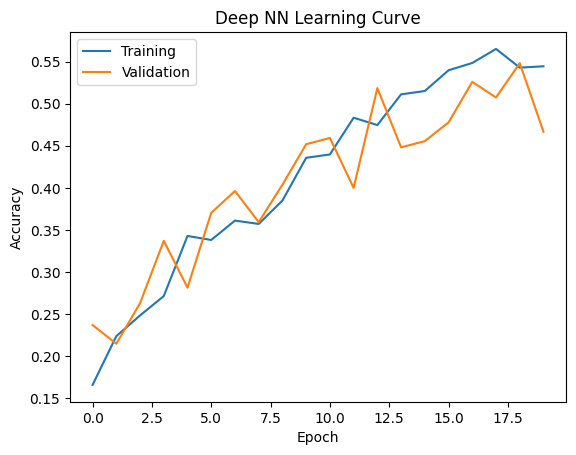

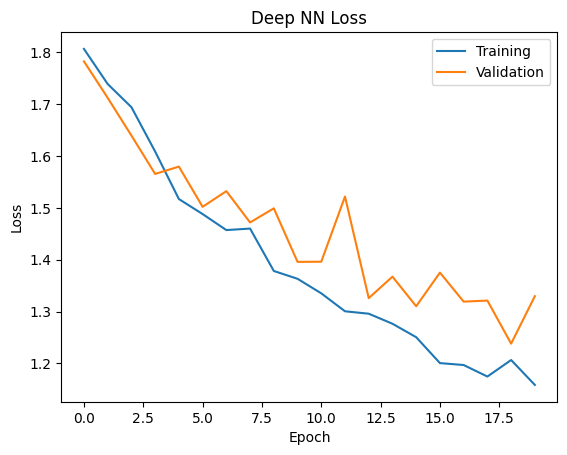

In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
 deep_model.parameters(),
 lr=0.001
)

def train_one_epoch(model, loader, optimizer, loss_fn):
 model.train()
 total_loss = 0
 correct = 0
 total = 0
 for images, labels in loader:
  images = images.to(device)
  labels = labels.to(device)
  outputs = model(images)
  loss = loss_fn(outputs, labels)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  total_loss += loss.item()
  predictions = outputs.argmax(dim=1)
  correct += (predictions == labels).sum().item()
  total += labels.size(0)
 return total_loss / len(loader), correct / total

def evaluate(model, loader, loss_fn):
 model.eval()
 total_loss = 0
 correct = 0
 total = 0
 with torch.no_grad():
  for images, labels in loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    loss = loss_fn(outputs, labels)
    total_loss += loss.item()
    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)
 return total_loss / len(loader), correct / total

epochs = 20
dnn_train_loss = []
dnn_val_loss = []
dnn_train_acc = []
dnn_val_acc = []
for epoch in range(epochs):
 train_loss, train_acc = train_one_epoch(
  deep_model, train_loader, optimizer, loss_fn
 )
 val_loss, val_acc = evaluate(
  deep_model, val_loader, loss_fn
 )
 dnn_train_loss.append(train_loss)
 dnn_val_loss.append(val_loss)
 dnn_train_acc.append(train_acc)
 dnn_val_acc.append(val_acc)

 print(
  f"Epoch {epoch+1:02d} | "
  f"Train Acc: {train_acc:.3f} | "
  f"Val Acc: {val_acc:.3f}"
 )

plt.plot(dnn_train_acc, label="Training")
plt.plot(dnn_val_acc, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep NN Learning Curve")
plt.legend()
plt.show()

plt.plot(dnn_train_loss, label="Training")
plt.plot(dnn_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep NN Loss")
plt.legend()
plt.show()


Question 7. Does the model appear to be learning?

Yes, the training accuracy increased from ~16.6 to 54.4% over 20 epochs, while loss decreases. However, the final accuracy remains low, suggesting model struggles to learn the more complex features.

Question 8. Is there evidence of overfitting?

Yes, at the later epochs, training loss continues decreasing yet validation loss fluctuates and generally remains higher.

Question 9. At approximately which epoch does validation performance stop improving?

It did not reach a clear stable plateau, highest record of ~54.8% happened at epoch 19 before falling to 46.7% at epoch 20, indicating unstable validation performance.

# Part III

Section 23,24,25,26,27,28,29

In [7]:
nn.MaxPool2d(2)

class CNN(nn.Module):
 def __init__(self):
  super().__init__()
  self.features = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2)
  )
  self.classifier = nn.Sequential(
    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 128),
    nn.ReLU(),
    nn.Linear(128, 6)
  )
 def forward(self, x):
  x = self.features(x)
  x = self.classifier(x)
  return x

cnn_model = CNN().to(device)
print(cnn_model)
print("CNN parameters:", count_parameters(cnn_model))

#Creating the table of the question



CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)
CNN parameters: 548486


| Model | Trainable Parameters |
| --- | --- |
| Deep NN | 1065670 |
| CNN | 548486 |

Question 10. Which model has more trainable parameters?

The Deep NN contains more trainable parameters, with 1,065,670 compared to 548,486 for the CNN. The CNN has approximately 48.5% fewer parameters.

Question 11. Why can a CNN process an image effectively without connecting every input pixel to every hidden neuron?

CNNs use convolutional filters to detect local features such as edges, cracks, and textures. The same filters are shared across different image locations, allowing the network to recognize patterns without requiring separate connections for every pixel. Pooling further reduces the spatial dimensions and computational requirements.

Section 30,31

Epoch 01 | Train Acc: 0.298 | Val Acc: 0.378
Epoch 02 | Train Acc: 0.455 | Val Acc: 0.507
Epoch 03 | Train Acc: 0.594 | Val Acc: 0.522
Epoch 04 | Train Acc: 0.638 | Val Acc: 0.637
Epoch 05 | Train Acc: 0.687 | Val Acc: 0.611
Epoch 06 | Train Acc: 0.736 | Val Acc: 0.711
Epoch 07 | Train Acc: 0.780 | Val Acc: 0.711
Epoch 08 | Train Acc: 0.820 | Val Acc: 0.822
Epoch 09 | Train Acc: 0.838 | Val Acc: 0.807
Epoch 10 | Train Acc: 0.803 | Val Acc: 0.796
Epoch 11 | Train Acc: 0.891 | Val Acc: 0.863
Epoch 12 | Train Acc: 0.890 | Val Acc: 0.893
Epoch 13 | Train Acc: 0.833 | Val Acc: 0.756
Epoch 14 | Train Acc: 0.890 | Val Acc: 0.859
Epoch 15 | Train Acc: 0.929 | Val Acc: 0.863
Epoch 16 | Train Acc: 0.913 | Val Acc: 0.907
Epoch 17 | Train Acc: 0.941 | Val Acc: 0.896
Epoch 18 | Train Acc: 0.933 | Val Acc: 0.867
Epoch 19 | Train Acc: 0.943 | Val Acc: 0.878
Epoch 20 | Train Acc: 0.942 | Val Acc: 0.926


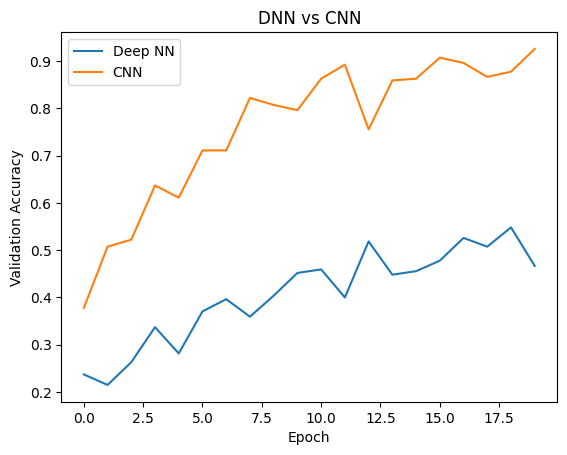

In [8]:
cnn_optimizer = torch.optim.Adam(
  cnn_model.parameters(),
  lr=0.001
)
cnn_train_loss = []
cnn_val_loss = []
cnn_train_acc = []
cnn_val_acc = []
for epoch in range(epochs):
  train_loss, train_acc = train_one_epoch(
    cnn_model, train_loader, cnn_optimizer, loss_fn
  )
  val_loss, val_acc = evaluate(
    cnn_model, val_loader, loss_fn
  )
  cnn_train_loss.append(train_loss)
  cnn_val_loss.append(val_loss)
  cnn_train_acc.append(train_acc)
  cnn_val_acc.append(val_acc)
  print(
    f"Epoch {epoch+1:02d} | "
    f"Train Acc: {train_acc:.3f} | "
    f"Val Acc: {val_acc:.3f}"
  )

plt.plot(dnn_val_acc, label="Deep NN")
plt.plot(cnn_val_acc, label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("DNN vs CNN")
plt.legend()
plt.show()

Question 12. Which model learns faster?

CNN apparently learns much faster and reaches a validation accuracy of 70% by epch 6, whereas DNN never reaches 60% after 20 epochs.

Question 13. Which achieves better validation performance?

The CNN achieves significantly better validation performance, reaching approximately 92.6% validation accuracy at its best epoch, compared with approximately 54.8% for the Deep NN.

Question 14. Which appears more stable during training?

The CNN appears more stable overall. Its validation accuracy improves more consistently, particularly during the early epochs, although some fluctuations remain. The Deep NN displays less consistent validation improvement and has a larger generalization gap near the end of training.

# Part IV

Section 32,33,34

In [9]:
dnn_test_loss, dnn_test_acc = evaluate(
 deep_model, test_loader, loss_fn
)
cnn_test_loss, cnn_test_acc = evaluate(
 cnn_model, test_loader, loss_fn
)
print("DNN Test Accuracy:", dnn_test_acc)
print("CNN Test Accuracy:", cnn_test_acc)

all_labels = []
all_predictions = []
cnn_model.eval()
with torch.no_grad():
 for images, labels in test_loader:
  images = images.to(device)
  outputs = cnn_model(images)
  predictions = outputs.argmax(dim=1)
  all_labels.extend(labels.numpy())
  all_predictions.extend(predictions.cpu().numpy())

print(
 classification_report(
  all_labels,
  all_predictions,
  target_names=dataset.classes
 )
)


DNN Test Accuracy: 0.48518518518518516
CNN Test Accuracy: 0.9259259259259259
                 precision    recall  f1-score   support

        crazing       0.98      0.96      0.97        51
      inclusion       0.87      0.80      0.84        41
        patches       1.00      1.00      1.00        42
 pitted_surface       0.84      0.92      0.88        52
rolled_in_scale       0.95      0.98      0.96        41
      scratches       0.93      0.88      0.90        43

       accuracy                           0.93       270
      macro avg       0.93      0.92      0.93       270
   weighted avg       0.93      0.93      0.93       270



|Model|Test Accuracy|
| --- | --- |
|Deep NN|48.52%|
|CNN|92.59%|

Question 15. Which class has the highest recall?

Patches has the highest recall of 1.00, meaning all 42 examples of this class in the test set were classified correctly.

Question 16. Which class has the lowest recall?

Inclusion has the lowest recall of 0.80, meaning approximately 19.5% of the actual inclusion samples were incorrectly classified.

Question 17. Why might recall be particularly important in an industrial defect-detection system?

High recall helps minimize missed defects or incorrect identification of important defect categories. Poor recall can allow defects to escape the appropriate inspection or corrective process, potentially increasing quality, reliability, and safety risks.

Section 35

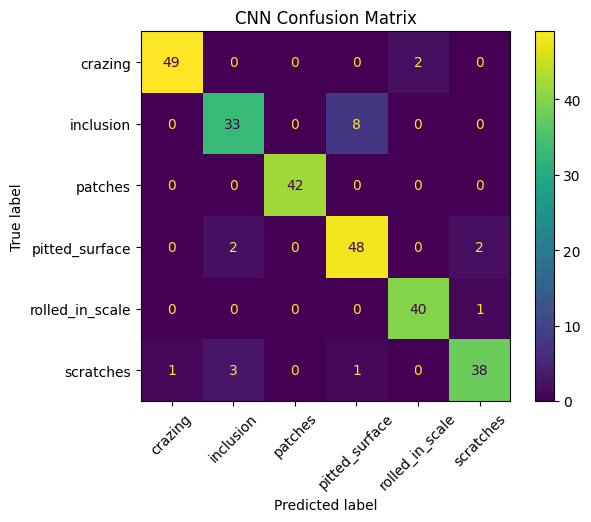

In [15]:
cm = confusion_matrix(all_labels, all_predictions)
cm_display = ConfusionMatrixDisplay(
 confusion_matrix=cm,
 display_labels=dataset.classes
)
cm_display.plot(xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.show()


Question 18. Which two defect types are most frequently confused?

Inclusion and pitted surface are the most frequently confused classes. Eight inclusion samples were incorrectly classified as pitted surface, while two pitted surface samples were classified as inclusion.

Question 19. Can you find a possible visual or mechanical explanation?

Both inclusions and pitted surfaces can produce dark, irregular markings on steel. Inclusions result from foreign material embedded in the surface, while pitted surfaces contain small cavities. At the reduced image resolution, these different physical defects can have similar visual appearances.

Section 36,37

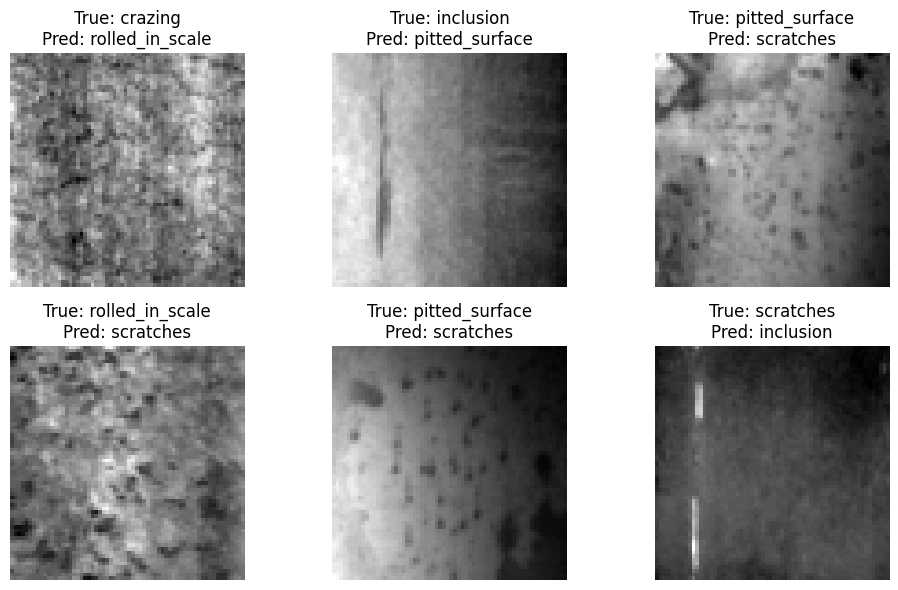

In [16]:
cnn_model.eval()
mistakes = []
with torch.no_grad():
 for images, labels in test_loader:
  outputs = cnn_model(images.to(device))
  predictions = outputs.argmax(dim=1).cpu()
  for image, true, pred in zip(images, labels, predictions):
    if true != pred:
      mistakes.append((image, true, pred))

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, item in zip(axes.flat, mistakes[:6]):
 image, true, pred = item
 ax.imshow(image.squeeze(), cmap="gray")
 ax.set_title(
  f"True: {dataset.classes[true]}\n"
  f"Pred: {dataset.classes[pred]}"
 )
 ax.axis("off")
plt.tight_layout()
plt.show()


|True Class|CNN Prediction|Possible Explaination|
| --- | --- | --- |
|Crazing|Rolled in Scale|Both display irregular, interconnected dark textures|
|Pitted surface|Scratches|Groups of elongated pits can resemble narrow scratches|
|Scratches|Inclusion|Short or fragmented scratch marks may resemble embedded material|

Question 20. Are the errors random, or do certain classes appear repeatedly?

The errors are not completely random. Pitted surface appears repeatedly among the incorrect predictions, particularly when classified as scratches. This suggests the CNN has difficulty distinguishing localized pits from elongated surface markings.

# Part V

Section 38,39,40

Deep NN: What relationship exists among all these pixel values?

CNN: What local visual patterns exist, and how can they be combined?



|Characteristic|Deep NN|CNN|
| --- | --- | --- |
|Input representation|Flattened pixels|2D image|
|Uses spatial relationships|Limited|Yes|
|Local feature extraction|No|Yes|
|Weight sharing|No|Yes|
|Test accuracy|48.52%|92.59%|
|Parameter count|1065670|548486|

The CNN achieved 44.07 percentage points higher test accuracy while using approximately 48.5% fewer trainable parameters. This demonstrates the advantage of convolutional feature extraction and spatial structure preservation for image classification.

# Part VI

Section 41,42,43,44,45,46

In [12]:
!pip install -q gradio

import gradio as gr

from PIL import Image
def predict_defect(image):
 image = transform(image)
 image = image.unsqueeze(0)
 image = image.to(device)
 cnn_model.eval()
 with torch.no_grad():
  outputs = cnn_model(image)
  probabilities = torch.softmax(outputs, dim=1)[0]
 results = {}
 for class_name, probability in zip(
  dataset.classes,
  probabilities.cpu().numpy()
 ):
  results[class_name] = float(probability)
 return results

app = gr.Interface(
 fn=predict_defect,
 inputs=gr.Image(type="pil"),
 outputs=gr.Label(num_top_classes=6),
 title="Steel Surface Defect Classifier",
 description=(
  "Upload an image of a steel surface and "
  "the CNN will predict the defect type."
 )
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bbaf66fa52e09263be.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


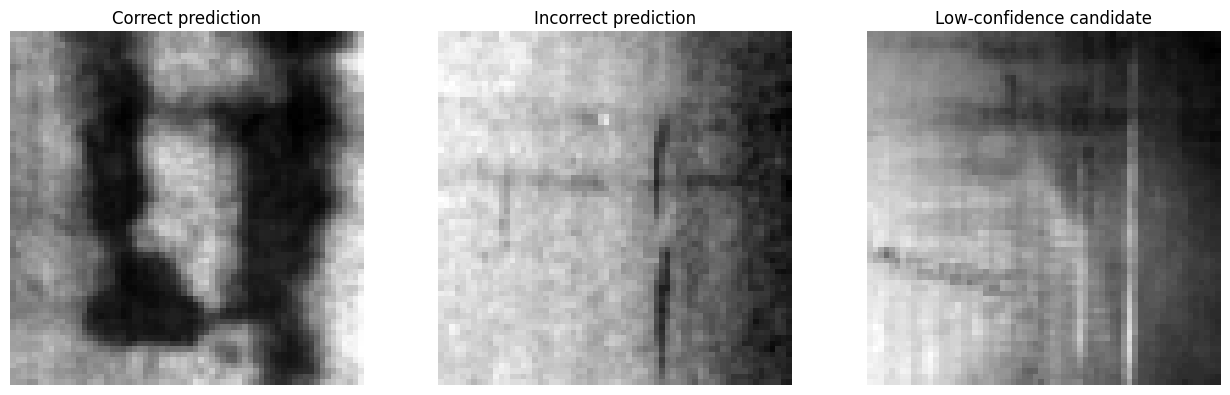

,Image,True Class,Predicted Class,Confidence
0,Pa_21.bmp,patches,patches,100.00%
1,In_251.bmp,inclusion,pitted_surface,98.58%
2,Sc_84.bmp,scratches,pitted_surface,37.71%


Original test images copied to: /content/lab4_test_samples


In [14]:

from pathlib import Path
import shutil
import pandas as pd

# Evaluate all images in the existing test set
records = []
cnn_model.eval()
test_position = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images.to(device))
        probabilities = torch.softmax(outputs, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        for j in range(len(labels)):
            true_id = int(labels[j].item())
            pred_id = int(predictions[j].item())
            original_idx = test_set.indices[test_position]
            file_path = dataset.samples[original_idx][0]

            records.append({
                "test_idx": test_position,
                "file_path": file_path,
                "true_class": dataset.classes[true_id],
                "predicted_class": dataset.classes[pred_id],
                "confidence": float(confidences[j].item()),
                "correct": true_id == pred_id
            })
            test_position += 1

# Select three distinct examples
correct = max(
    (r for r in records if r["correct"]),
    key=lambda r: r["confidence"]
)

incorrect = max(
    (r for r in records if not r["correct"]),
    key=lambda r: r["confidence"]
)

used = {correct["test_idx"], incorrect["test_idx"]}

ambiguous = min(
    (r for r in records if r["test_idx"] not in used),
    key=lambda r: r["confidence"]
)

selected = [
    ("Correct prediction", correct),
    ("Incorrect prediction", incorrect),
    ("Low-confidence candidate", ambiguous)
]

# Display images and copy original files
sample_dir = Path("/content/lab4_test_samples")
sample_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
table_rows = []

for ax, (category, record) in zip(axes, selected):
    image, _ = test_set[record["test_idx"]]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(category)
    ax.axis("off")

    filename = Path(record["file_path"]).name

    shutil.copy2(
        record["file_path"],
        sample_dir / filename
    )

    table_rows.append({
        "Image": filename,
        "True Class": record["true_class"],
        "Predicted Class": record["predicted_class"],
        "Confidence": f'{record["confidence"]:.2%}'
    })

plt.tight_layout()
plt.show()

# Generate Section 45 results table
results_table = pd.DataFrame(table_rows)
from IPython.display import display as show_table
show_table(results_table)

print("Original test images copied to:", sample_dir)


Question 21. Find one example where the model gives substantial confidence to an incorrect prediction.

The CNN incorrectly classified In_251.bmp as pitted surface with 98.58% confidence, even though its true class was inclusion. This demonstrates that high confidence does not guarantee a correct prediction.

Question 22. Would you allow this classifier to automatically reject expensive manufactured components
without human review? Explain.

No. Although the CNN achieved 92.59% test accuracy, it still made 20 incorrect predictions among 270 test images, including a highly confident error. Furthermore, the dataset contains only defective samples, so the classifier cannot determine whether a component is acceptable. Human review and further validation would be required before deploying it for automated rejection.

# Part VII

Section 47,48

Hypothesis:

Increasing the number of convolutional filters may improve validation accuracy by allowing the CNN to learn more complex surface-defect features. However, the larger number of parameters may also increase computational cost and the risk of overfitting.

Epoch 01 | Train Acc: 0.324 | Val Acc: 0.433
Epoch 02 | Train Acc: 0.559 | Val Acc: 0.522
Epoch 03 | Train Acc: 0.609 | Val Acc: 0.552
Epoch 04 | Train Acc: 0.635 | Val Acc: 0.641
Epoch 05 | Train Acc: 0.703 | Val Acc: 0.667
Epoch 06 | Train Acc: 0.768 | Val Acc: 0.756
Epoch 07 | Train Acc: 0.802 | Val Acc: 0.704
Epoch 08 | Train Acc: 0.805 | Val Acc: 0.741
Epoch 09 | Train Acc: 0.848 | Val Acc: 0.822
Epoch 10 | Train Acc: 0.873 | Val Acc: 0.837
Epoch 11 | Train Acc: 0.862 | Val Acc: 0.833
Epoch 12 | Train Acc: 0.902 | Val Acc: 0.885
Epoch 13 | Train Acc: 0.887 | Val Acc: 0.752
Epoch 14 | Train Acc: 0.888 | Val Acc: 0.900
Epoch 15 | Train Acc: 0.874 | Val Acc: 0.811
Epoch 16 | Train Acc: 0.905 | Val Acc: 0.896
Epoch 17 | Train Acc: 0.925 | Val Acc: 0.856
Epoch 18 | Train Acc: 0.920 | Val Acc: 0.904
Epoch 19 | Train Acc: 0.942 | Val Acc: 0.926
Epoch 20 | Train Acc: 0.917 | Val Acc: 0.930


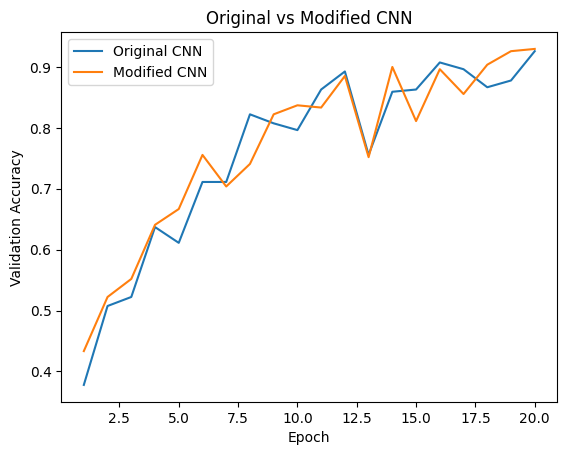

,Model,Final Validation Accuracy,Test Accuracy,Parameters
0,Original CNN,92.59%,92.59%,548486
1,Modified CNN,92.96%,89.63%,839558


In [17]:

# Part VII - Modified CNN Experiment
# Increase convolutional filters from 16/32/64 to 24/48/96

class ModifiedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 24, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(24, 48, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(48, 96, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(96 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 6)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


torch.manual_seed(42)

modified_model = ModifiedCNN().to(device)

modified_optimizer = torch.optim.Adam(
    modified_model.parameters(),
    lr=0.001
)

modified_train_acc = []
modified_val_acc = []

# Train for the same 20 epochs
for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
        modified_model, train_loader,
        modified_optimizer, loss_fn
    )

    val_loss, val_acc = evaluate(
        modified_model, val_loader, loss_fn
    )

    modified_train_acc.append(train_acc)
    modified_val_acc.append(val_acc)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Acc: {train_acc:.3f} | "
        f"Val Acc: {val_acc:.3f}"
    )

# Final test evaluation
modified_test_loss, modified_test_acc = evaluate(
    modified_model, test_loader, loss_fn
)

# Compare validation learning curves
plt.plot(
    range(1, epochs + 1),
    cnn_val_acc,
    label="Original CNN"
)
plt.plot(
    range(1, epochs + 1),
    modified_val_acc,
    label="Modified CNN"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Original vs Modified CNN")
plt.legend()
plt.show()

# Section 48 comparison table
import pandas as pd
from IPython.display import display as show_table

comparison = pd.DataFrame({
    "Model": ["Original CNN", "Modified CNN"],
    "Final Validation Accuracy": [
        f"{cnn_val_acc[-1]:.2%}",
        f"{modified_val_acc[-1]:.2%}"
    ],
    "Test Accuracy": [
        f"{cnn_test_acc:.2%}",
        f"{modified_test_acc:.2%}"
    ],
    "Parameters": [
        count_parameters(cnn_model),
        count_parameters(modified_model)
    ]
})

show_table(comparison)


Question 23. Did the result support your hypothesis?

The hypothesis was partially supported. Increasing the number of convolutional filters improved final validation accuracy from 92.59% to 92.96%, suggesting that the additional filters may help extract more complex features. However, test accuracy decreased from 92.59% to 89.63%, so the increased model complexity did not improve overall generalization in this experiment.

Question 24. Did the more complicated model necessarily perform better?

No. Although the modified CNN had approximately 53.1% more trainable parameters and slightly higher validation accuracy, it performed worse on the test set. This demonstrates that increasing model complexity does not guarantee better performance on unseen data. Additional parameters may introduce unnecessary complexity without providing a consistent improvement in generalization.

Secction 49

R1. Why is a fully connected neural network not naturally suited to image data?

A fully connected network flattens the image into a one-dimensional vector, losing the explicit spatial arrangement of pixels. This makes local patterns harder to learn efficiently and requires a large number of parameters.

R2. What is the advantage of applying the same convolutional filter at many image locations?

Sharing filters allows the CNN to detect similar features regardless of their location in the image. It also reduces the required number of parameters and improves computational efficiency.

R3. What does pooling accomplish?

Pooling reduces the spatial dimensions of feature maps while retaining important information. This reduces computational requirements and makes the network less sensitive to small changes in feature positions.

R4. Why should test data not be repeatedly used while modifying the CNN?

Repeatedly evaluating and modifying a model based on test performance can indirectly cause overfitting to the test set. The test set should remain independent to provide a reliable estimate of generalization performance.

R5. Why is a confusion matrix more informative than accuracy alone for this problem?

Accuracy only shows the overall proportion of correct predictions. A confusion matrix identifies which defect classes are being confused, allowing engineers to investigate specific failure modes that could affect manufacturing quality.

R6. Which failure would be more serious in an industrial setting: incorrectly rejecting a good component
or accepting a defective component? Does the answer always remain the same?

Accepting a defective component may be more serious when it creates safety or reliability risks. However, incorrectly rejecting expensive components can cause significant financial losses. The relative consequences depend on the component's application, defect severity, and manufacturing requirements.

R7. What additional evidence would you require before deploying this classifier on an actual production
line?

The classifier would require evaluation using larger datasets collected under realistic operating conditions, including different lighting, surface finishes, and defect variations. Testing should also include acceptable components, confidence calibration, and analysis of failure consequences before automated deployment.

In [18]:

# Generating Results Figures

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig_dir = Path("/content/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Figure 1 - DNN learning curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(dnn_train_acc, label="Training")
axes[0].plot(dnn_val_acc, label="Validation")
axes[0].set_title("DNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(dnn_train_loss, label="Training")
axes[1].plot(dnn_val_loss, label="Validation")
axes[1].set_title("DNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

fig.tight_layout()
fig.savefig(fig_dir / "dnn_learning_curves.png",
            dpi=150, bbox_inches="tight")
plt.close(fig)

# Figure 2 - CNN experiment comparison
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(cnn_val_acc, label="Original CNN")
ax.plot(modified_val_acc, label="Modified CNN")
ax.set_title("CNN Validation Accuracy Comparison")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Accuracy")
ax.legend()

fig.tight_layout()
fig.savefig(fig_dir / "cnn_comparison.png",
            dpi=150, bbox_inches="tight")
plt.close(fig)

# Figure 3 - Original CNN confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

cm_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

cm_plot.plot(ax=ax, xticks_rotation=45,
             values_format="d", cmap="Blues")
ax.set_title("CNN Confusion Matrix")

fig.tight_layout()
fig.savefig(fig_dir / "cnn_confusion_matrix.png",
            dpi=150, bbox_inches="tight")
plt.close(fig)

print("Figures saved:")
for file in fig_dir.glob("*.png"):
    print(file.name)


Figures saved:
cnn_confusion_matrix.png
dnn_learning_curves.png
cnn_comparison.png
